# 04 — Avaliação e Interpretação

O conjunto de teste é utilizado somente depois da seleção da Random Forest + Class Weight. Aqui a análise deixa de ser apenas técnica e passa a ser de negócio.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import RANDOM_STATE, FIGURES, METRICS, MODELS, TARGET

FIGURES.mkdir(parents=True, exist_ok=True)
METRICS.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
print("RANDOM_STATE =", RANDOM_STATE)

import joblib
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, RocCurveDisplay
from sklearn.model_selection import train_test_split
from src.config import TEST_SIZE, QUANTITATIVE_FEATURES, BINARY_FEATURES, CATEGORICAL_FEATURES
from src.data import load_processed
from src.evaluation import score_percent, save_metrics

RANDOM_STATE = 42


In [2]:
df=load_processed(); X=df.drop(columns=["ID",TARGET]); y=df[TARGET].astype(int); ids=df["ID"]
X_train,X_test,y_train,y_test,ids_train,ids_test=train_test_split(X,y,ids,test_size=TEST_SIZE,stratify=y,random_state=RANDOM_STATE)
modelo_path=MODELS/"modelo_final_random_forest_credito.joblib"
if not modelo_path.exists(): raise FileNotFoundError("Execute primeiro notebooks/03_modelagem.ipynb.")
modelo=joblib.load(modelo_path)

## 1. Métricas no conjunto de teste

Acurácia sozinha engana em base desbalanceada. A avaliação inclui Precision, Recall, F1-score, ROC-AUC, especificidade e a matriz de erros.

In [3]:
y_pred=modelo.predict(X_test); y_score=modelo.predict_proba(X_test)[:,1]
metricas=pd.DataFrame([score_percent(y_test,y_pred,y_score)]); display(metricas.round(2))
print(classification_report(y_test,y_pred,target_names=["Bom pagador (0)","Mau pagador (1)"],digits=4,zero_division=0))
save_metrics(metricas,"metricas_teste_final.csv")

,Accuracy_%,Precision_%,Recall_%,F1_%,Especificidade_%,TN,FP,FN,TP,ROC_AUC_%
0,84.13,41.09,51.86,45.85,88.93,5126,638,413,445,79.8


                 precision    recall  f1-score   support

Bom pagador (0)     0.9254    0.8893    0.9070      5764
Mau pagador (1)     0.4109    0.5186    0.4585       858

       accuracy                         0.8413      6622
      macro avg     0.6682    0.7040    0.6828      6622
   weighted avg     0.8588    0.8413    0.8489      6622



## 2. Justificativa das métricas

A classe positiva representa 12,96% da base. Recall mede quantos maus pagadores são encontrados, Precision mede a qualidade das sinalizações, F1 equilibra ambos e ROC-AUC mede a capacidade de ordenação em diferentes thresholds. Sem função financeira explícita, o projeto não inventa um custo relativo entre FP e FN.

## 3. Matriz de confusão

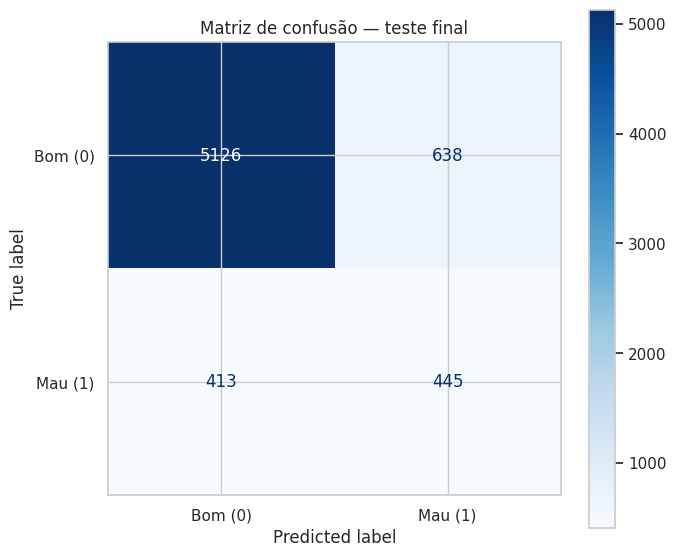

In [4]:
fig,ax=plt.subplots(figsize=(7,6)); ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=["Bom (0)","Mau (1)"],cmap="Blues",values_format="d",ax=ax); ax.set_title("Matriz de confusão — teste final"); plt.tight_layout(); plt.savefig(FIGURES/"06_matriz_confusao_teste.png",dpi=160,bbox_inches="tight"); plt.show()

**Leitura.** O teste contém 5.764 bons e 858 maus pagadores. O modelo acerta **5.126** bons e identifica **445** maus, com **638 FP** e **413 FN**. O Recall final é **51,86%** e a especificidade **88,93%**.

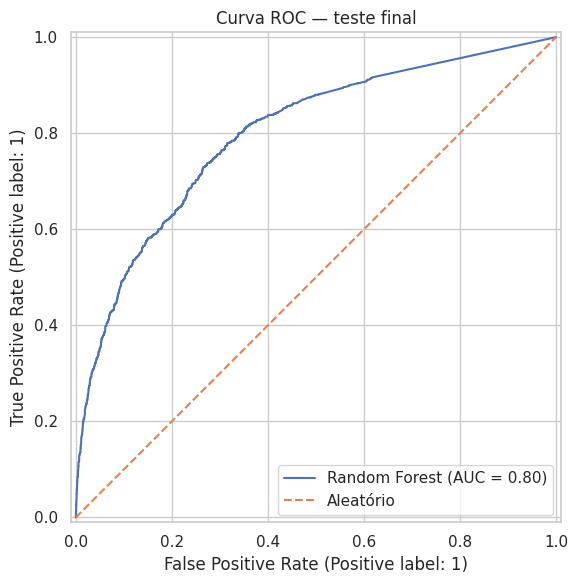

In [5]:
fig,ax=plt.subplots(figsize=(7,6)); RocCurveDisplay.from_predictions(y_test,y_score,ax=ax,name="Random Forest"); ax.plot([0,1],[0,1],linestyle="--",label="Aleatório"); ax.set_title("Curva ROC — teste final"); ax.legend(); plt.tight_layout(); plt.savefig(FIGURES/"07_curva_roc_teste.png",dpi=160,bbox_inches="tight"); plt.show()

**Interpretação.** O ROC-AUC final é aproximadamente **79,80%**, superior à referência aleatória de 50%. Isso confirma capacidade de discriminação relevante em dados independentes. A ROC complementa a matriz porque avalia o ranking do modelo em múltiplos thresholds.

## 4. Importância das variáveis

,Variavel,Importancia,Importancia_%,Acumulada_%
0,AGE_YEARS,0.22,22.00,22.00
1,AMT_INCOME_TOTAL,0.16,15.67,37.67
2,EMPLOYMENT_YEARS,0.15,14.84,52.51
3,OCCUPATION_TYPE,0.11,11.09,63.60
4,NAME_FAMILY_STATUS,0.05,5.05,68.65
5,NAME_EDUCATION_TYPE,0.04,4.49,73.15
6,NAME_INCOME_TYPE,0.04,4.21,77.36
7,CNT_FAM_MEMBERS,0.03,3.40,80.76
8,NAME_HOUSING_TYPE,0.03,3.01,83.77
9,FLAG_PHONE,0.03,2.91,86.68


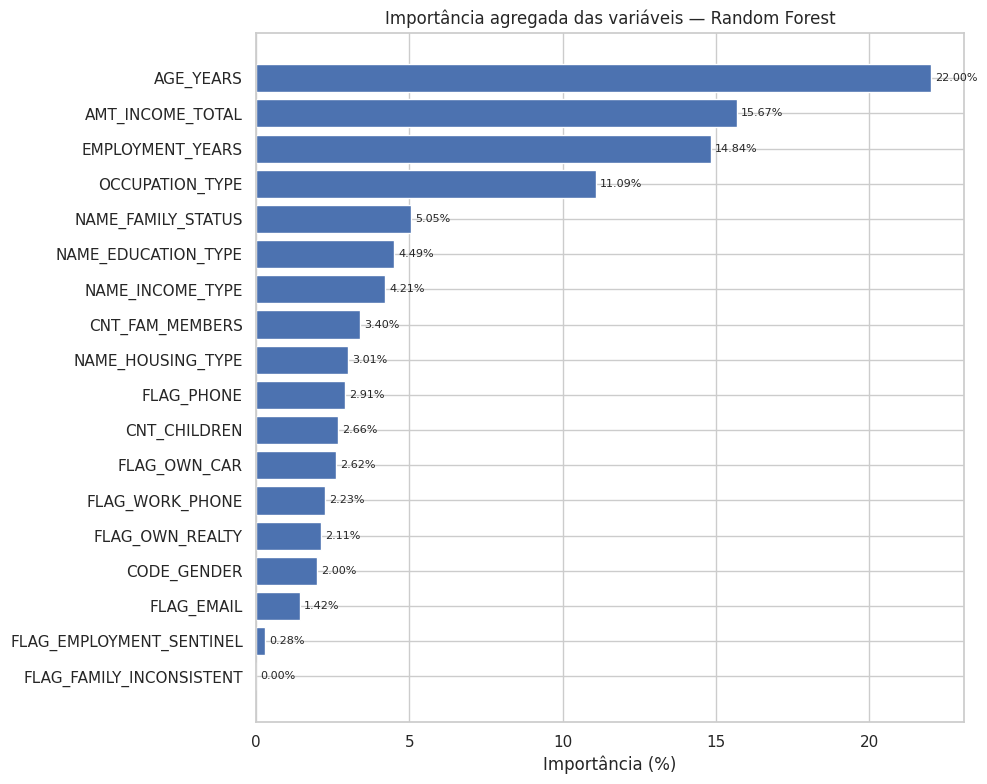

In [6]:
preprocessador=modelo.named_steps["preprocessamento"]; floresta=modelo.named_steps["modelo"]; importancias=floresta.feature_importances_; encoder=preprocessador.named_transformers_["categoricas"]
origens=list(QUANTITATIVE_FEATURES)+list(BINARY_FEATURES)
for var,categorias in zip(CATEGORICAL_FEATURES,encoder.categories_): origens.extend([var]*len(categorias))
assert len(origens)==len(importancias)
imp=pd.DataFrame({"Variavel":origens,"Importancia":importancias}); imp_agg=imp.groupby("Variavel",as_index=False)["Importancia"].sum().sort_values("Importancia",ascending=False).reset_index(drop=True); imp_agg["Importancia_%"]=imp_agg["Importancia"]*100; imp_agg["Acumulada_%"]=imp_agg["Importancia_%"].cumsum(); display(imp_agg.round(2)); save_metrics(imp_agg,"feature_importance.csv")
plot_imp=imp_agg.sort_values("Importancia_%"); fig,ax=plt.subplots(figsize=(10,8)); barras=ax.barh(plot_imp["Variavel"],plot_imp["Importancia_%"]); ax.set_title("Importância agregada das variáveis — Random Forest"); ax.set_xlabel("Importância (%)"); ax.bar_label(barras,fmt="%.2f%%",padding=3,fontsize=8); plt.tight_layout(); plt.savefig(FIGURES/"08_feature_importance.png",dpi=160,bbox_inches="tight"); plt.show()

**Leitura.** As maiores importâncias agregadas são idade (**22,00%**), renda (**15,67%**), tempo de emprego (**14,84%**) e ocupação (**11,09%**). A medida indica relevância preditiva dentro da Random Forest, não causalidade nem direção do efeito.

## 5. Implicações práticas

A solução pode atuar como **apoio à decisão**, priorizando análises adicionais para perfis com maior score de risco. O threshold padrão identifica pouco mais da metade da classe positiva e preserva quase 89% dos bons pagadores. Em produção, o threshold deveria ser definido com custos reais de aprovar um mau pagador e rejeitar um bom, sem reutilizar o conjunto de teste para ajuste.

## 6. Limitações

- target depende da regra operacional de 30+ dias;
- desbalanceamento continua relevante;
- custos de FP/FN não foram fornecidos;
- Feature Importance não prova causalidade;
- antes de uso real seriam necessários calibração, validação temporal, monitoramento de drift e governança de crédito.

**Conclusão.** A Random Forest + Class Weight apresentou no teste independente **Accuracy 84,13%, Precision 41,09%, Recall 51,86%, F1 45,85% e ROC-AUC 79,80%**, comportamento compatível com a validação e adequado como resultado final do Tech Challenge.